# Reconnaissance vocale : du signal audio au texte, étape par étape

**Projet 25 – Audio** · *Explain speech-to-text and demonstrate transcription of a short recording.*

Ce notebook déroule, sur un vrai enregistrement, chacune des transformations qu'effectue un système de reconnaissance vocale moderne (Whisper, OpenAI) :

```
Voix ─▶ [1] signal numérique ─▶ [2] prétraitement ─▶ [3] spectrogramme log-Mel
     ─▶ [4] encodeur ─▶ [5] décodeur ─▶ [6] recherche ─▶ [7] texte
```

On termine par une **évaluation** (WER) de trois tailles de modèle. L'application interactive est dans `app.py`.

In [1]:
import json, time, warnings
from pathlib import Path
warnings.filterwarnings("ignore", message="IProgress")

import librosa
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from transformers import WhisperForConditionalGeneration, WhisperProcessor
from transformers.utils import logging as hf_logging

from stt.audio import SR, charger_audio, infos_fichier
from stt.evaluate import wer
from stt.features import HOP, N_FFT, N_MELS, log_mel
from stt.transcribe import MODELES, detecter_langue, transcrire, vers_srt

hf_logging.set_verbosity_error()
hf_logging.disable_progress_bar()
plt.rcParams.update({"figure.dpi": 110, "figure.figsize": (10, 3.2)})

FICHIER = "samples/exemple_fr.wav"      # ← remplace par ton propre enregistrement
MODELE = "openai/whisper-small"
REFERENCES = json.loads(Path("samples/references.json").read_text(encoding="utf-8"))

## Étape 1 — Le signal numérique

Le micro transforme la pression de l'air en tension électrique ; le convertisseur analogique-numérique la **mesure N fois par seconde** (échantillonnage) et code chaque mesure sur 16 bits (quantification).

Pour l'ordinateur, un son n'est donc qu'un **tableau 1D de nombres**.

In [2]:
infos = infos_fichier(FICHIER)
brut, sr_origine = librosa.load(FICHIER, sr=None, mono=False)

print(f"Format             : {infos['format']}")
print(f"Fréquence d'origine: {sr_origine} Hz  ({sr_origine} mesures par seconde)")
print(f"Canaux             : {infos['canaux']}")
print(f"Durée              : {infos['duree']:.2f} s")
print(f"Nombre d'échantillons : {brut.shape[-1]:,}".replace(",", " "))
print(f"10 premières valeurs après 1 s : {np.round(brut[..., sr_origine:sr_origine+10], 4)}")

Format             : WAV / PCM_16
Fréquence d'origine: 44100 Hz  (44100 mesures par seconde)
Canaux             : 1
Durée              : 9.45 s
Nombre d'échantillons : 416 704
10 premières valeurs après 1 s : [-0.0064  0.0076  0.0168  0.0182  0.0147  0.0114  0.0098  0.0082  0.004
 -0.0029]


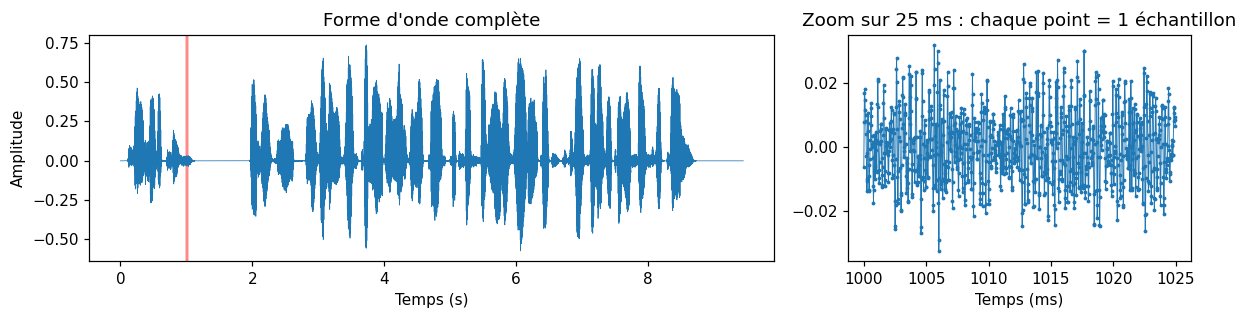

In [3]:
t = np.arange(brut.shape[-1]) / sr_origine
debut = int(1.0 * sr_origine)
fenetre = slice(debut, debut + int(0.025 * sr_origine))   # 25 ms

fig, (a, b) = plt.subplots(1, 2, figsize=(11, 3), gridspec_kw={"width_ratios": [2, 1]})
a.plot(t, brut, lw=0.5)
a.axvspan(t[fenetre][0], t[fenetre][-1], color="red", alpha=0.3)
a.set(title="Forme d'onde complète", xlabel="Temps (s)", ylabel="Amplitude")
b.plot(t[fenetre] * 1000, brut[fenetre], ".-", ms=3, lw=0.6)
b.set(title="Zoom sur 25 ms : chaque point = 1 échantillon", xlabel="Temps (ms)")
plt.tight_layout(); plt.show()

## Étape 2 — Prétraitement

Whisper attend un format unique :

* **mono** (une seule piste) ;
* **16 kHz** : d'après le théorème de Nyquist-Shannon, on capte les fréquences jusqu'à 8 kHz, ce qui couvre l'essentiel de la parole ;
* des valeurs flottantes dans **[-1, 1]** ;
* des fenêtres de **30 s** exactement : on complète avec du silence (ou on découpe).

In [4]:
audio = charger_audio(FICHIER)               # mono + rééchantillonnage à 16 kHz
audio_30s = np.pad(audio, (0, max(0, 30 * SR - len(audio))))[: 30 * SR]

print(f"Avant : {brut.shape[-1]:>9,} échantillons à {sr_origine} Hz".replace(",", " "))
print(f"Après : {len(audio):>9,} échantillons à {SR} Hz  (÷ {sr_origine / SR:.2f})".replace(",", " "))
print(f"Complété à 30 s : {len(audio_30s):_} échantillons".replace("_", " ")
      + f", dont {1 - len(audio)/len(audio_30s):.0%} de silence")
print(f"Amplitudes dans [{audio.min():.2f}, {audio.max():.2f}]")

Avant :   416 704 échantillons à 44100 Hz
Après :   151 186 échantillons à 16000 Hz  (÷ 2.76)
Complété à 30 s : 480 000 échantillons, dont 69% de silence
Amplitudes dans [-0.56, 0.73]


## Étape 3 — Extraction de caractéristiques : le spectrogramme log-Mel

L'onde brute dit *quand* le son est fort, pas *quelles fréquences* il contient — or ce sont les fréquences qui distinguent un « a » d'un « i ». On passe donc dans le domaine fréquentiel, en quatre sous-étapes.

### 3a. Fenêtrage + transformée de Fourier d'une trame
On découpe le signal en trames de **25 ms** (400 échantillons), pondérées par une fenêtre de Hann pour éviter les discontinuités aux bords, puis on calcule leur spectre (FFT).

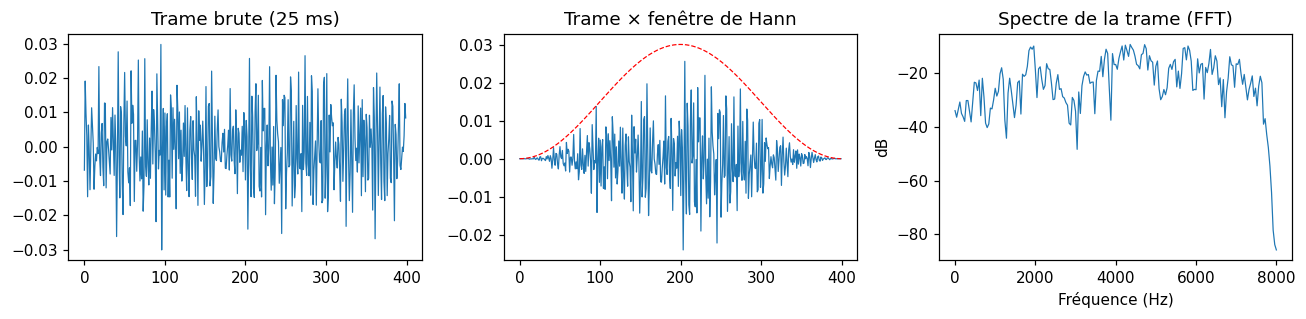

400 échantillons → 201 fréquences de 0 à 8000 Hz (pas de 40 Hz)


In [5]:
i0 = int(1.0 * SR)
trame = audio[i0 : i0 + N_FFT]
hann = np.hanning(N_FFT)
spectre = np.abs(np.fft.rfft(trame * hann))
freqs = np.fft.rfftfreq(N_FFT, 1 / SR)

fig, ax = plt.subplots(1, 3, figsize=(12, 3))
ax[0].plot(trame, lw=0.8); ax[0].set_title("Trame brute (25 ms)")
ax[1].plot(trame * hann, lw=0.8); ax[1].plot(hann * np.abs(trame).max(), "r--", lw=0.8)
ax[1].set_title("Trame × fenêtre de Hann")
ax[2].plot(freqs, 20 * np.log10(spectre + 1e-9), lw=0.8)
ax[2].set(title="Spectre de la trame (FFT)", xlabel="Fréquence (Hz)", ylabel="dB")
plt.tight_layout(); plt.show()
print(f"{N_FFT} échantillons → {len(freqs)} fréquences de 0 à {freqs[-1]:.0f} Hz (pas de {freqs[1]:.0f} Hz)")

### 3b. STFT : on répète l'opération toutes les 10 ms
La transformée de Fourier à court terme (STFT) fait glisser la fenêtre avec un pas de **10 ms** (160 échantillons). On obtient une **image** : temps en abscisse, fréquence en ordonnée, énergie en couleur.

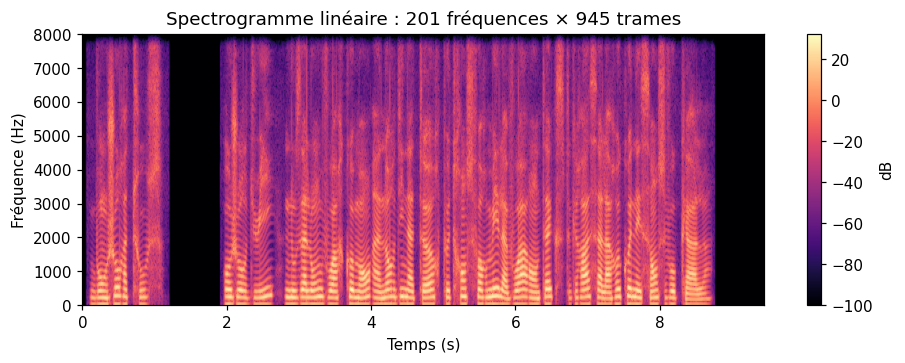

In [6]:
stft = librosa.stft(audio, n_fft=N_FFT, hop_length=HOP, window="hann", pad_mode="reflect")
puissance = np.abs(stft) ** 2
duree = len(audio) / SR

plt.figure(figsize=(10, 3.2))
plt.imshow(10 * np.log10(puissance + 1e-10), origin="lower", aspect="auto", cmap="magma",
           extent=[0, duree, 0, SR / 2])
plt.colorbar(label="dB"); plt.xlabel("Temps (s)"); plt.ylabel("Fréquence (Hz)")
plt.title(f"Spectrogramme linéaire : {puissance.shape[0]} fréquences × {puissance.shape[1]} trames")
plt.show()

### 3c. Échelle Mel : imiter l'oreille humaine
L'oreille distingue très bien 200 Hz de 300 Hz, mais pas 7 000 Hz de 7 100 Hz. L'échelle Mel, $m = 2595 \log_{10}(1 + f/700)$, reproduit cette perception. On regroupe les 201 fréquences en **80 bandes** avec des filtres triangulaires : étroits dans les graves, larges dans les aigus.

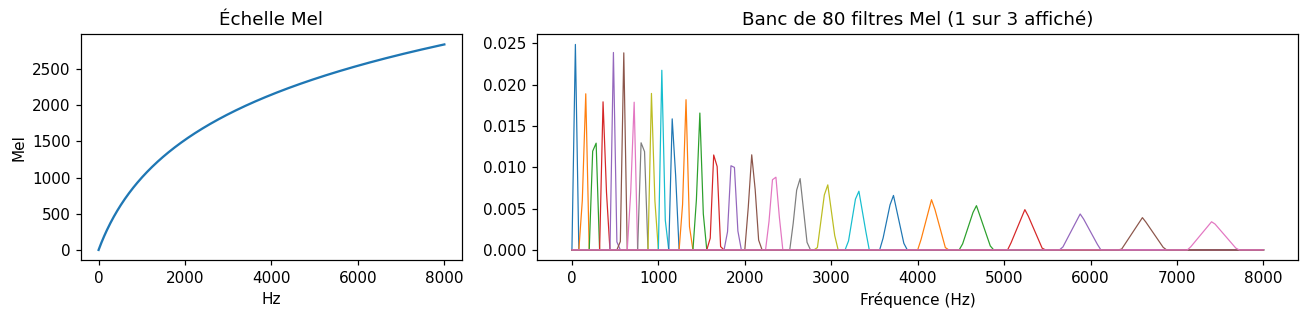

Matrice des filtres : (80, 201)  →  (80 × 201) @ (201 × trames) = (80 × trames)


In [7]:
filtres = librosa.filters.mel(sr=SR, n_fft=N_FFT, n_mels=N_MELS)
f = np.linspace(0, SR / 2, 500)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 3), gridspec_kw={"width_ratios": [1, 2]})
a.plot(f, 2595 * np.log10(1 + f / 700)); a.set(title="Échelle Mel", xlabel="Hz", ylabel="Mel")
for k in range(0, N_MELS, 3):
    b.plot(freqs, filtres[k], lw=0.8)
b.set(title=f"Banc de {N_MELS} filtres Mel (1 sur 3 affiché)", xlabel="Fréquence (Hz)")
plt.tight_layout(); plt.show()
print(f"Matrice des filtres : {filtres.shape}  →  ({N_MELS} × 201) @ (201 × trames) = (80 × trames)")

### 3d. Logarithme et comparaison avec Whisper
On prend le logarithme (la perception du volume est logarithmique), on plafonne la dynamique à 8 ordres de grandeur, puis on met à l'échelle. Notre fonction `log_mel` (dans `stt/features.py`) ré-implémente ces calculs à la main ; on vérifie qu'elle donne **la même matrice** que l'extracteur officiel de Whisper.

Entrée de Whisper : (1, 80, 3000)  →  80 bandes Mel × 3000 trames (30 s × 100 trames/s)
Notre implémentation : (80, 3000), écart maximal avec l'officielle = 1.19e-05


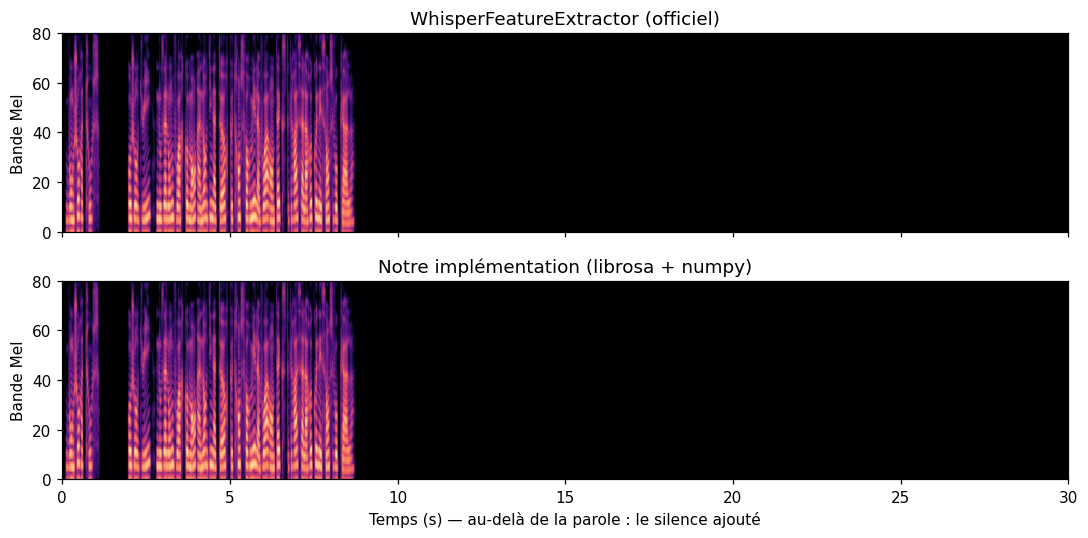

In [8]:
processeur = WhisperProcessor.from_pretrained(MODELE)
officiel = processeur(audio, sampling_rate=SR, return_tensors="pt").input_features   # (1, 80, 3000)
maison = log_mel(audio_30s)

print(f"Entrée de Whisper : {tuple(officiel.shape)}  →  80 bandes Mel × 3000 trames (30 s × 100 trames/s)")
print(f"Notre implémentation : {maison.shape}, écart maximal avec l'officielle = "
      f"{np.abs(maison - officiel[0].numpy()).max():.2e}")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
for a, m, titre in [(ax[0], officiel[0].numpy(), "WhisperFeatureExtractor (officiel)"),
                    (ax[1], maison, "Notre implémentation (librosa + numpy)")]:
    a.imshow(m, origin="lower", aspect="auto", cmap="magma", extent=[0, 30, 0, N_MELS])
    a.set(title=titre, ylabel="Bande Mel")
ax[1].set_xlabel("Temps (s) — au-delà de la parole : le silence ajouté")
plt.tight_layout(); plt.show()

> **Lien avec la vision artificielle** : à partir d'ici, le son est devenu une **image en niveaux de gris de 80 × 3000 pixels**. Toute la suite est un réseau de neurones de vision : convolutions, puis Transformer (comme un Vision Transformer).

## Étape 4 — L'encodeur

L'encodeur de Whisper :
1. applique **2 convolutions 1D** (la seconde avec un pas de 2, qui divise le nombre de trames par 2) ;
2. ajoute un **encodage de position** ;
3. passe le tout dans une pile de blocs **Transformer** (auto-attention + MLP).

On pose des « crochets » (hooks) sur les couches pour observer la forme des données à chaque passage.

In [9]:
modele = WhisperForConditionalGeneration.from_pretrained(MODELE, dtype=torch.float32).eval()
cfg = modele.config
n_enc = sum(p.numel() for p in modele.model.encoder.parameters())
n_dec = sum(p.numel() for p in modele.model.decoder.parameters())
print(f"{MODELE} : {cfg.encoder_layers} couches d'encodeur, {cfg.decoder_layers} couches de décodeur, "
      f"vecteurs de dimension {cfg.d_model}")
print(f"Paramètres : encodeur {n_enc/1e6:.0f} M, décodeur {n_dec/1e6:.0f} M")

formes = {}
crochets = [couche.register_forward_hook(lambda m, i, o, n=nom: formes.__setitem__(n, tuple(o.shape)))
            for nom, couche in [("conv1", modele.model.encoder.conv1),
                                ("conv2 (pas de 2)", modele.model.encoder.conv2)]]
with torch.no_grad():
    sortie_encodeur = modele.model.encoder(officiel)
for c in crochets:
    c.remove()

print(f"\nlog-Mel              : {tuple(officiel.shape)}")
for nom, forme in formes.items():
    print(f"{nom:<21}: {forme}")
print(f"sortie de l'encodeur : {tuple(sortie_encodeur.last_hidden_state.shape)}  "
      f"→ 1500 positions, une toutes les 20 ms")

openai/whisper-small : 12 couches d'encodeur, 12 couches de décodeur, vecteurs de dimension 768
Paramètres : encodeur 88 M, décodeur 154 M



log-Mel              : (1, 80, 3000)
conv1                : (1, 768, 3000)
conv2 (pas de 2)     : (1, 768, 1500)
sortie de l'encodeur : (1, 1500, 768)  → 1500 positions, une toutes les 20 ms


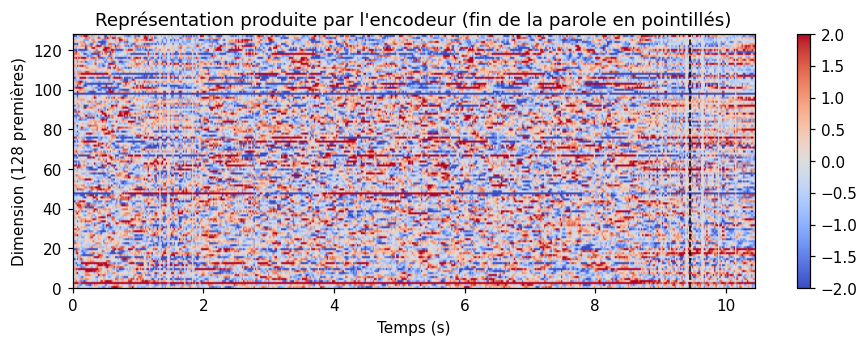

In [10]:
n_utiles = int(duree * 50)    # 50 positions par seconde
h = sortie_encodeur.last_hidden_state[0, : n_utiles + 50].numpy()
plt.figure(figsize=(10, 3))
plt.imshow(h.T[:128], aspect="auto", cmap="coolwarm", origin="lower",
           extent=[0, h.shape[0] / 50, 0, 128], vmin=-2, vmax=2)
plt.axvline(duree, color="k", ls="--", lw=1)
plt.xlabel("Temps (s)"); plt.ylabel("Dimension (128 premières)")
plt.title("Représentation produite par l'encodeur (fin de la parole en pointillés)")
plt.colorbar(); plt.show()

## Étape 5 — Le décodeur

Le décodeur est un Transformer **autorégressif** : il écrit le texte **un token à la fois**, en regardant les tokens déjà écrits et, par attention croisée, la sortie de l'encodeur. Il joue aussi le rôle de modèle de langue.

Whisper est piloté par des **tokens spéciaux** placés au début :

`<|startoftranscript|>` `<|langue|>` `<|transcribe|>` ou `<|translate|>` `<|notimestamps|>`

### 5a. Détection de la langue
On donne seulement `<|startoftranscript|>` au décodeur et on lit la probabilité qu'il attribue à chacun des 99 tokens de langue pour la position suivante.

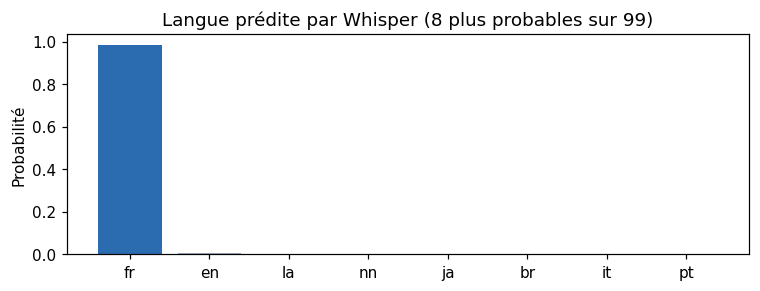

Langue détectée : fr (98.7%)


In [11]:
probas = detecter_langue(processeur, modele, audio, top=8)
codes, p = zip(*probas)
plt.figure(figsize=(8, 2.6))
plt.bar(codes, p, color=["#2b6cb0"] + ["#a0aec0"] * (len(p) - 1))
plt.ylabel("Probabilité"); plt.title("Langue prédite par Whisper (8 plus probables sur 99)")
plt.show()
print("Langue détectée :", codes[0], f"({p[0]:.1%})")
LANGUE = codes[0]

### 5b. Génération token par token
On ré-écrit la boucle de génération à la main (**décodage glouton**) : à chaque pas, on prend le token le plus probable et on le rajoute à l'entrée du décodeur, jusqu'au token de fin `<|endoftext|>`. L'encodeur n'est calculé qu'une seule fois.

In [12]:
tok = processeur.tokenizer
prefixe = ["<|startoftranscript|>", f"<|{LANGUE}|>", "<|transcribe|>", "<|notimestamps|>"]
ids = [tok.convert_tokens_to_ids(t) for t in prefixe]
fin = tok.convert_tokens_to_ids("<|endoftext|>")
print("Préfixe imposé :", list(zip(prefixe, ids)), "\n")

lignes = []
with torch.no_grad():
    for pas in range(100):
        logits = modele(encoder_outputs=sortie_encodeur,
                        decoder_input_ids=torch.tensor([ids])).logits[0, -1]
        proba = torch.softmax(logits, dim=-1)
        suivant = int(proba.argmax())
        lignes.append({"pas": pas + 1, "id": suivant, "token": repr(tok.decode([suivant])),
                       "probabilité": round(float(proba[suivant]), 3),
                       "texte jusqu'ici": tok.decode(ids[len(prefixe):] + [suivant])})
        ids.append(suivant)
        if suivant == fin:
            break

pd.set_option("display.max_colwidth", 90)
pd.DataFrame(lignes)

Préfixe imposé : [('<|startoftranscript|>', 50258), ('<|fr|>', 50265), ('<|transcribe|>', 50359), ('<|notimestamps|>', 50363)] 



,pas,id,token,probabilité,texte jusqu'ici
0,1,25431,' Bonjour',0.968,Bonjour
1,2,1531,' à',0.977,Bonjour à
2,3,8317,' tous',0.994,Bonjour à tous
3,4,13,'.',0.521,Bonjour à tous.
4,5,32650,' Aujourd',0.957,Bonjour à tous. Aujourd
5,6,6,"""'""",1.000,Bonjour à tous. Aujourd'
6,7,10556,'hui',1.000,Bonjour à tous. Aujourd'hui
7,8,11,"','",0.895,"Bonjour à tous. Aujourd'hui,"
8,9,4666,' nous',0.999,"Bonjour à tous. Aujourd'hui, nous"
9,10,34405,' allons',0.999,"Bonjour à tous. Aujourd'hui, nous allons"


## Étape 6 — Stratégie de recherche : glouton vs beam search

Le décodage glouton ne revient jamais sur un choix. Le **beam search** conserve à chaque pas les *k* hypothèses les plus probables et choisit à la fin la meilleure séquence complète : souvent plus juste, mais plus lent.

In [13]:
for faisceaux in (1, 5):
    t0 = time.perf_counter()
    with torch.no_grad():
        sortie = modele.generate(officiel, language=LANGUE, task="transcribe", num_beams=faisceaux)
    texte = tok.batch_decode(sortie, skip_special_tokens=True)[0].strip()
    nom = "glouton" if faisceaux == 1 else f"beam search (k={faisceaux})"
    print(f"{nom:<22} {time.perf_counter() - t0:5.2f} s  →  {texte}")

glouton                 4.30 s  →  Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer la voix en texte grâce à la reconnaissance vocale.


beam search (k=5)       9.77 s  →  Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer la voix en texte grâce à la reconnaissance vocale.


## Étape 7 — Post-traitement

Les identifiants de tokens sont reconvertis en texte (les tokens spéciaux sont retirés). Whisper sait aussi prédire des **tokens d'horodatage** (`<|0.00|>`, `<|2.40|>`…), qui permettent de découper le texte en segments et de produire des sous-titres.

In [14]:
print("Identifiants produits à l'étape 5b :\n ", ids, "\n")
print("Décodés avec les tokens spéciaux :\n ", tok.decode(ids, skip_special_tokens=False), "\n")
print("Texte final :\n ", tok.decode(ids, skip_special_tokens=True).strip(), "\n")

resultat = transcrire(audio, "small (244 M)", langue=LANGUE)
print("Sous-titres SRT :\n")
print(vers_srt(resultat.segments, resultat.duree_audio))

Identifiants produits à l'étape 5b :
  [50258, 50265, 50359, 50363, 25431, 1531, 8317, 13, 32650, 6, 10556, 11, 4666, 34405, 10695, 2871, 517, 4792, 13923, 374, 5977, 31782, 635, 37188, 465, 2487, 68, 31180, 1531, 635, 31073, 14431, 2329, 1220, 13, 50257] 

Décodés avec les tokens spéciaux :
  <|startoftranscript|><|fr|><|transcribe|><|notimestamps|> Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer la voix en texte grâce à la reconnaissance vocale.<|endoftext|> 

Texte final :
  Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer la voix en texte grâce à la reconnaissance vocale. 



Sous-titres SRT :

1
00:00:00,000 --> 00:00:09,000
Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer la voix en texte grâce à la reconnaissance vocale.



## Évaluation — Word Error Rate (WER)

$$\text{WER} = \frac{S + D + I}{N}$$

avec $S$ substitutions, $D$ suppressions (mots oubliés), $I$ insertions (mots ajoutés) et $N$ le nombre de mots de la référence. Le texte est normalisé (minuscules, sans ponctuation) avant la comparaison.

On compare les trois tailles de modèle sur tous les enregistrements de `samples/`.

In [15]:
mesures = []
for nom_modele in MODELES:
    for fichier, reference in REFERENCES.items():
        a = charger_audio(f"samples/{fichier}")
        r = transcrire(a, nom_modele)
        w = wer(reference, r.texte)
        mesures.append({"modèle": nom_modele, "fichier": fichier, "langue": r.langue,
                        "WER (%)": round(100 * w["wer"], 1), "temps (s)": round(r.temps_calcul, 2),
                        "facteur temps réel": round(r.facteur_temps_reel, 2),
                        "transcription": r.texte})
resultats = pd.DataFrame(mesures)
resultats

,modèle,fichier,langue,WER (%),temps (s),facteur temps réel,transcription
0,tiny (39 M),exemple_fr.wav,fr,0.0,1.30,0.14,"Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer l..."
1,tiny (39 M),exemple_fr_bruit.wav,fr,9.1,1.67,0.18,"bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur se transformer la ..."
2,tiny (39 M),exemple_en.wav,en,0.0,1.40,0.15,Speech recognition converts spoken language into written text. Modern systems use deep...
3,base (74 M),exemple_fr.wav,fr,0.0,2.84,0.30,"Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer l..."
4,base (74 M),exemple_fr_bruit.wav,fr,9.1,2.62,0.28,"Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur se transformer la ..."
5,base (74 M),exemple_en.wav,en,0.0,2.37,0.25,Speech recognition converts spoken language into written text. Modern systems use deep...
6,small (244 M),exemple_fr.wav,fr,0.0,7.25,0.77,"Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur peut transformer l..."
7,small (244 M),exemple_fr_bruit.wav,fr,4.5,8.02,0.85,"Bonjour à tous. Aujourd'hui, nous allons voir comment un ordinateur que transformer la..."
8,small (244 M),exemple_en.wav,en,0.0,8.23,0.86,Speech recognition converts spoken language into written text. Modern systems use deep...


,WER (%),temps (s),facteur temps réel
modèle,,,
tiny (39 M),3.03,1.46,0.16
base (74 M),3.03,2.61,0.28
small (244 M),1.50,7.83,0.83


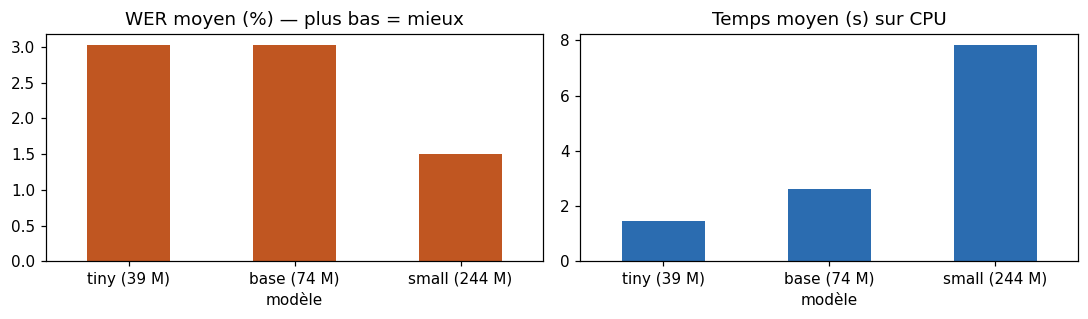

In [16]:
synthese = resultats.groupby("modèle", sort=False)[["WER (%)", "temps (s)", "facteur temps réel"]].mean().round(2)
display(synthese)

fig, (a, b) = plt.subplots(1, 2, figsize=(10, 3))
synthese["WER (%)"].plot.bar(ax=a, color="#c05621", rot=0, title="WER moyen (%) — plus bas = mieux")
synthese["temps (s)"].plot.bar(ax=b, color="#2b6cb0", rot=0, title="Temps moyen (s) sur CPU")
plt.tight_layout(); plt.show()

## Conclusion

| Étape | Entrée → sortie |
|---|---|
| 1. Numérisation | onde sonore → tableau de nombres (ici 44,1 kHz) |
| 2. Prétraitement | → mono 16 kHz, complété à 30 s (480 000 valeurs) |
| 3. Features | → spectrogramme log-Mel 80 × 3000 (une image) |
| 4. Encodeur | → 1500 vecteurs contextualisés |
| 5. Décodeur | → un token à la fois, guidé par les tokens spéciaux |
| 6. Recherche | glouton ou beam search |
| 7. Post-traitement | → texte, ponctuation, horodatage |

**Limites observées / connues** : hallucinations sur le silence et le bruit, qualité inégale selon les langues et dialectes (darija), noms propres, fenêtres de 30 s qui empêchent le vrai temps réel, pas d'identification des locuteurs.

> Les enregistrements fournis sont générés par synthèse vocale : remplace-les par **ta propre voix** (et mets à jour `samples/references.json`) pour des résultats plus réalistes.